# Transmission and detection limit calculation - Lithium metal

## Imports

Import the PyQNI framework

In [1]:
import sys
sys.path.append(r'C:\Software\pyqni\framework') # update path if necessary
from PyQNI import *

We will also use the *matplotlib* package to display charts and the *numpy* package to work with arrays.

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
font = {'family' : 'DejaVu Sans',
        'weight' : 'normal',
        'size'   : 12}

We define the energy neutron energy range of interest from 1 meV to 1 eV

In [3]:
e_vals = np.geomspace(1e-3, 1, 401)

##  Create the compounds

In [129]:
cu = compound(composition={'Cu':1}, spec_weight=8.96)
e, xs_cu_tot = cu.cross_sections(e_vals=e_vals)

fe = compound(composition={'Fe':1}, spec_weight=7.85)
e, xs_fe_tot = fe.cross_sections(e_vals=e_vals)

quartz = compound(composition={'Si':1, 'O':2}, spec_weight=2.2)
e, xs_quartz_tot = quartz.cross_sections(e_vals=e_vals)

peek = compound(composition={'H-1-ENDF':12*0.999855, 'H-2':12*0.000145, 'O':3, 'C':19, }, spec_weight=1.32)
e, xs_peek_tot = peek.cross_sections(e_vals=e_vals)

pvdf = compound(composition={'H-1-ENDF':2*0.999855, 'H-2':2*0.000145, 'F':2, 'C':2, }, spec_weight=1.78)
e, xs_pvdf_tot = pvdf.cross_sections(e_vals=e_vals)

li_nat = compound(composition={'Li':1}, spec_weight=0.534)
e, xs_li_nat_tot = li_nat.cross_sections(e_vals=e_vals)

li_6 = compound(composition={'Li-6':1}, mol_dens=li_nat.mol_dens())
# li_6 = compound(composition={'Li-6':1}, spec_weight=0.3)
e, xs_li_6_tot = li_6.cross_sections(e_vals=e_vals)

li_7 = compound(composition={'Li-7':1}, mol_dens=li_nat.mol_dens())
e, xs_li_7_tot = li_7.cross_sections(e_vals=e_vals)

steel = compound(composition={'Fe':97.2, 'C':0.92, 'Mn':0.6, 'Si':0.59, 'S':0.34, 'P':0.36}, spec_weight=7.85)
e, xs_steel = steel.cross_sections(e_vals=e_vals)

li2co3 = compound(composition={'Li-7':2, 'C':1, 'O':3}, mol_dens=li_nat.mol_dens())
e, xs_li2co3 = li2co3.cross_sections(e_vals=e_vals)

lih = compound(composition={'Li-6':1, 'H-1-ENDF':1}, mol_dens=li_nat.mol_dens())
e, xs_lih = lih.cross_sections(e_vals=e_vals)


water = compound(composition={'H-1-ENDF':2, 'O':1}, spec_weight=1)
e, xs_water = water.cross_sections(e_vals=e_vals)

In [126]:
print(lih.spec_weight)

<bound method compound.spec_weight of <PyQNI.compound object at 0x00000255A78809A0>>


## Linear attenuation coefficients

And we plot the to get an overview

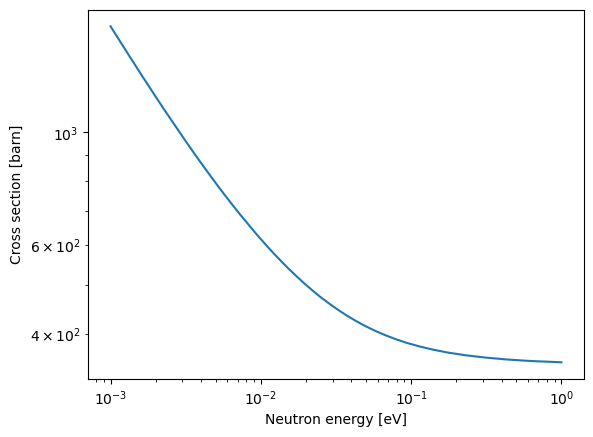

In [92]:
plt.loglog(e, xs_peek_tot)

plt.xlabel('Neutron energy [eV]')
plt.ylabel('Cross section [barn]')
plt.show()

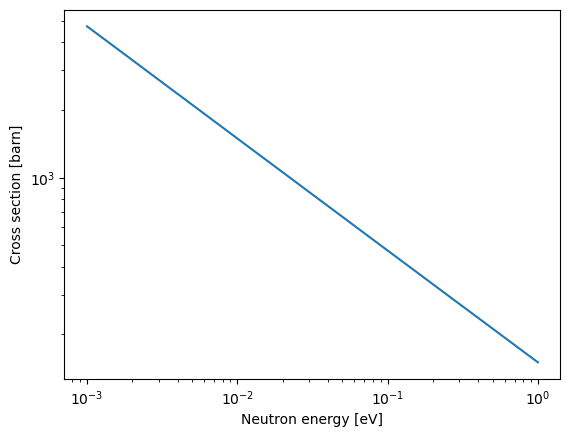

In [93]:
plt.loglog(e, xs_li_6_tot)

plt.xlabel('Neutron energy [eV]')
plt.ylabel('Cross section [barn]')
plt.show()

## Beamline and detector

We get the beamline spectrum

In [94]:
icon = beam('ICON')

In [95]:
boa = beam('BOA')

In [96]:
beamline = icon

We specify the scintillator material to get the effective neutron spectrum

In [97]:
from PyQNI_scintillators import gadox_sc
gadox_30 = detector(gadox_sc, thickness=0.003)

Plot them as a function of neutron energy to check

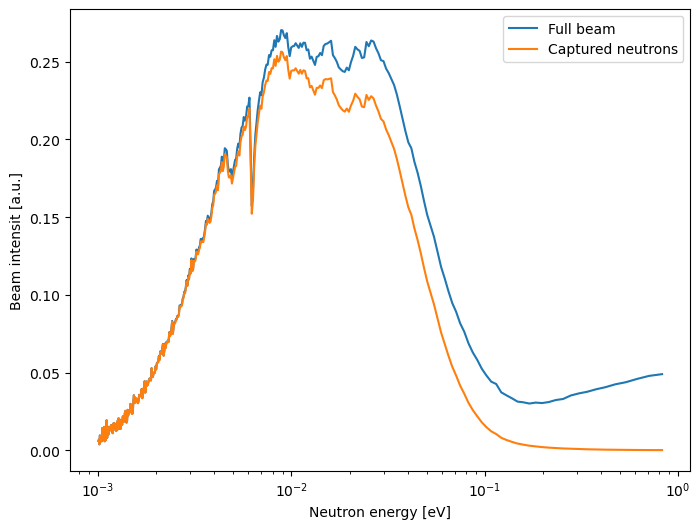

In [98]:
plt.figure(figsize=(8,6))
x_spec,_,y_spec = beamline.spectrum()
x_effspec,_,y_effspec = beamline.eff_spectrum(gadox_30)
plt.semilogx(x_spec, y_spec)
plt.semilogx(x_effspec,y_effspec)
plt.xlabel('Neutron energy [eV]')
plt.ylabel('Beam intensit [a.u.]')
plt.legend(['Full beam', 'Captured neutrons'])
plt.show()

## Computation of transmission

We get converter functions for each of the copunds. The converter functions compute the effective transmission (including beam hardening effects) for a set a thicknesses and interpolate inbetween.

In [99]:
conv_cu_nat = cu.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [100]:
conv_fe_nat = fe.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [101]:
conv_quartz = quartz.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [102]:
conv_peek = peek.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [103]:
conv_pvdf = pvdf.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [104]:
conv_li_nat = li_nat.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [105]:
conv_li_6 = li_6.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [106]:
conv_steel = steel.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

In [107]:
conv_al = al.get_converter(beam=beamline, detector=gadox_30, param='thickness', result='trans')

We define the thickness range of interest from 0 to 1000 $\mu$m (numbers are specified in cm)

In [108]:
thick_range = np.linspace(0, 0.01, 1001)

We compute the transmission for this thickness range

In [109]:
trans_cu_nat = conv_cu_nat(thick_range)
trans_fe_nat = conv_fe_nat(thick_range)
trans_quartz = conv_quartz(thick_range)
trans_peek = conv_peek(thick_range)
trans_pvdf = conv_pvdf(thick_range)
trans_li_nat = conv_li_nat(thick_range)
trans_li_6 = conv_li_6(thick_range)
trans_li_6 = conv_li_6(thick_range)
trans_steel = conv_steel(thick_range)
trans_al = conv_al(thick_range)

And plot the results

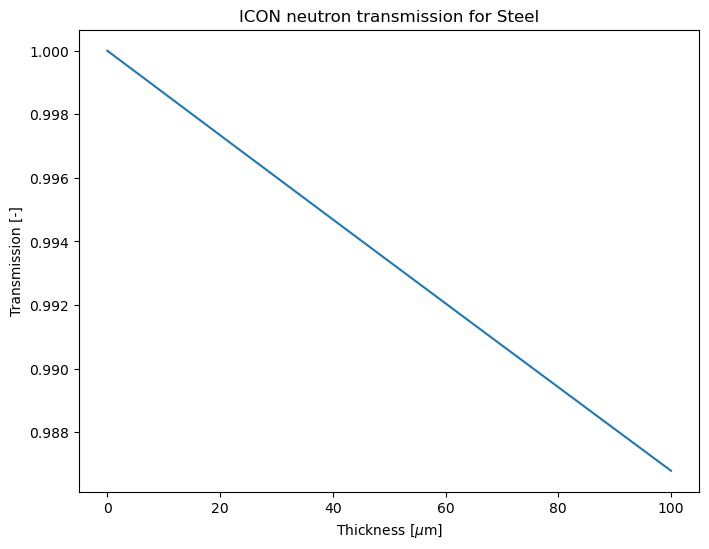

In [110]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_steel)
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.title('ICON neutron transmission for Steel')
plt.show()

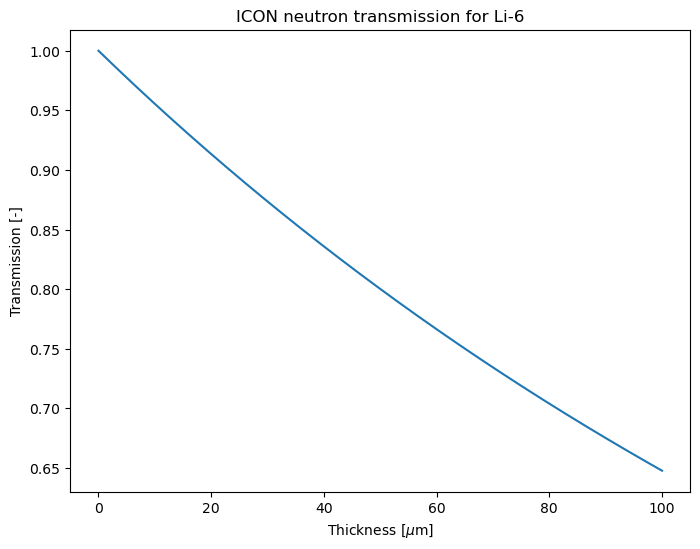

[1.         0.99999763 0.99999527 ... 0.9976415  0.99763914 0.99763677]


In [111]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_li_6)
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.title('ICON neutron transmission for Li-6')
plt.show()
print(trans_quartz)

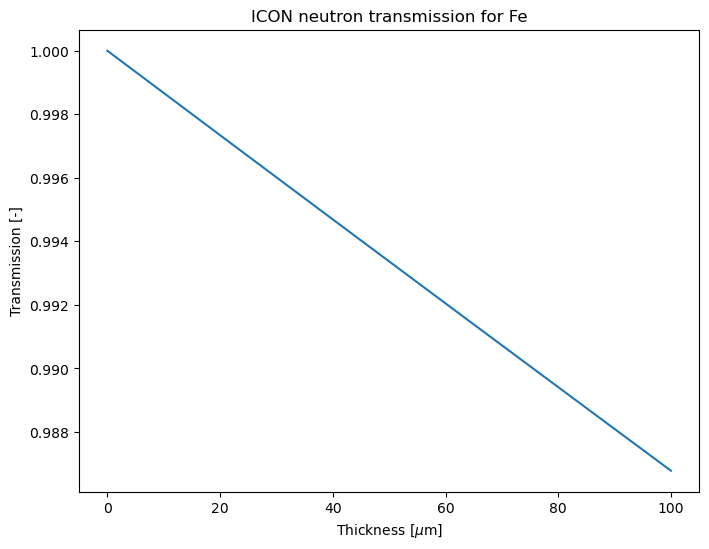

In [112]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_fe_nat)
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.title('ICON neutron transmission for Fe')
plt.show()

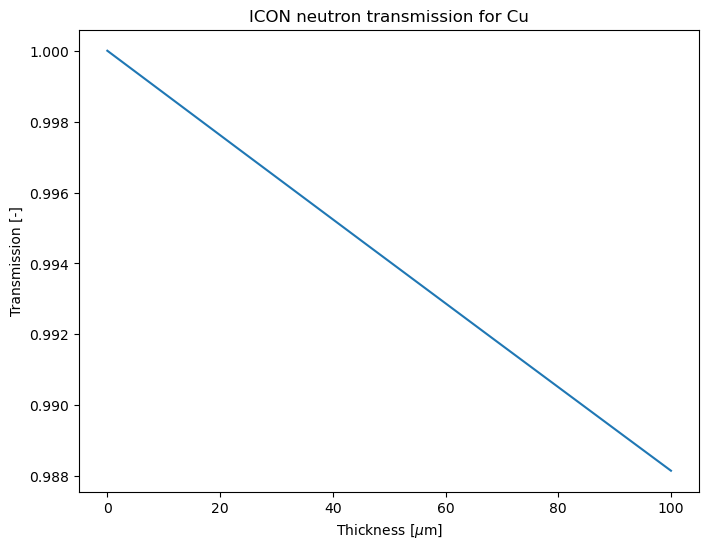

In [113]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_cu_nat)
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.title('ICON neutron transmission for Cu')
plt.show()

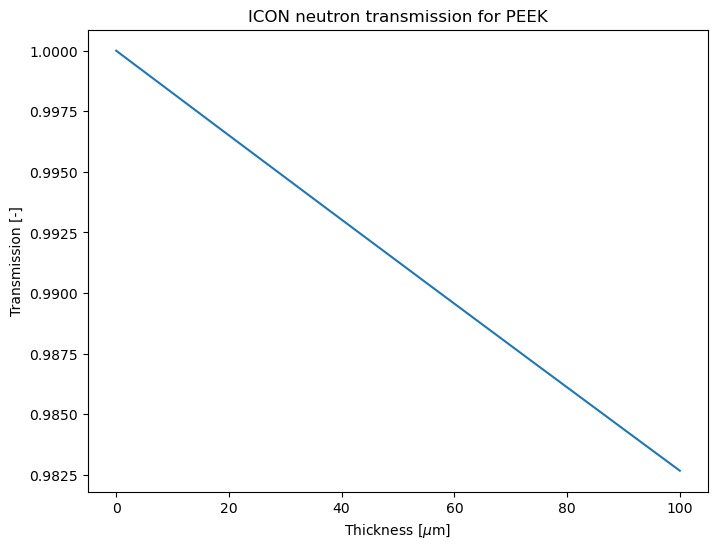

In [114]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_peek)
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.title('ICON neutron transmission for PEEK')
plt.show()

A detailled look at the transmission for thin layers (0-20 $\mu$m)

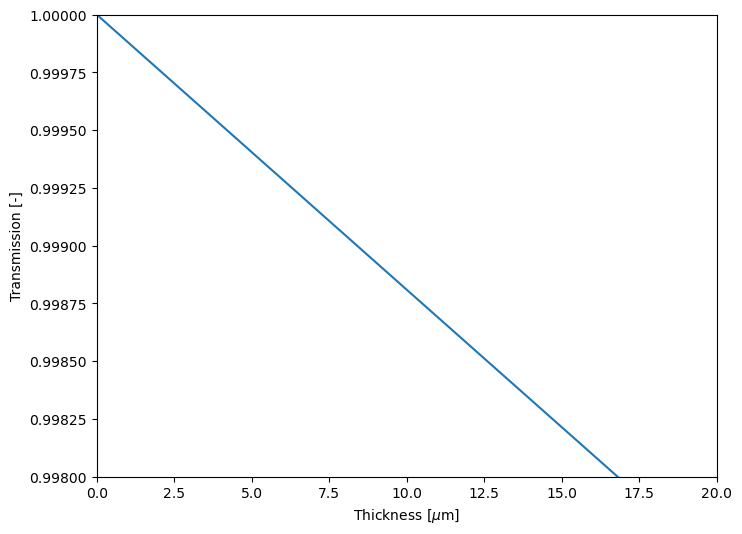

In [115]:
plt.figure(figsize=(8,6))
plt.plot(thick_range*1e4, trans_cu_nat)
plt.xlim((0,20))
plt.ylim((0.998,1))
plt.xlabel('Thickness [$\mu$m]')
plt.ylabel('Transmission [-]')
plt.show()

We also output the values of the linear attenuation coefficients:

In [130]:
lac_li_6 = li_6.eff_att_coeff(beamline, gadox_30)
lac_li_7 = li_7.eff_att_coeff(beamline, gadox_30)
lac_li_nat = li_nat.eff_att_coeff(beamline, gadox_30)
lac_peek = peek.eff_att_coeff(beamline, gadox_30)
lac_cu = cu.eff_att_coeff(beamline, gadox_30)
lac_steel = steel.eff_att_coeff(beamline, gadox_30)
lac_al = al.eff_att_coeff(beamline, gadox_30)
lac_li2co3 = li2co3.eff_att_coeff(beamline, gadox_30)
lac_lih = lih.eff_att_coeff(beamline, gadox_30)
lac_water = water.eff_att_coeff(beamline, gadox_30)

print('Attenuation coefficient for li_6: {:.4g}'.format(lac_li_6))
print('Attenuation coefficient for li_7: {:.4g}'.format(lac_li_7))
print('Attenuation coefficient for li_nat: {:.4g}'.format(lac_li_nat))
print('Attenuation coefficient for peek: {:.4g}'.format(lac_peek))
print('Attenuation coefficient for cu: {:.4g}'.format(lac_cu))
print('Attenuation coefficient for steel: {:.4g}'.format(lac_steel))
print('Attenuation coefficient for al: {:.4g}'.format(lac_al))
print('Attenuation coefficient for li2co3: {:.4g}'.format(lac_li2co3))
print('Attenuation coefficient for lih: {:.4g}'.format(lac_lih))
print('Attenuation coefficient for water: {:.4g}'.format(lac_water))

Attenuation coefficient for li_6: 70.48
Attenuation coefficient for li_7: 0.05836
Attenuation coefficient for li_nat: 5.34
Attenuation coefficient for peek: 1.749
Attenuation coefficient for cu: 1.192
Attenuation coefficient for steel: 1.33
Attenuation coefficient for al: 0.1138
Attenuation coefficient for li2co3: 0.9492
Attenuation coefficient for lih: 72.49
Attenuation coefficient for water: 3.034


And the lithium thicknesses corresponding to the few contrast values:

In [90]:
contrast_vals = [0.001,0.002,0.005,0.01]
for c in contrast_vals:
    print('Thickness for {:g}% contrast (PEEK): {:g} um'.format(100*c, -np.log(1-c)/lac_peek*10000))
    print('Thickness for {:g}% contrast (PEEK): {:g} um'.format(100*c, -np.log(1-c)/lac_peek*10000))

Thickness for 0.1% contrast (PEEK): 5.72054 um
Thickness for 0.1% contrast (PEEK): 5.72054 um
Thickness for 0.2% contrast (PEEK): 11.4468 um
Thickness for 0.2% contrast (PEEK): 11.4468 um
Thickness for 0.5% contrast (PEEK): 28.6601 um
Thickness for 0.5% contrast (PEEK): 28.6601 um
Thickness for 1% contrast (PEEK): 57.4646 um
Thickness for 1% contrast (PEEK): 57.4646 um


## Detection limit

We assume that we are limited by the statistical noise and will compute the standard deviation of the local thickness measurement as a function of exposure time and spatial resolution.

In [29]:
def calc_dlim(n_flux, dqe, resol, exp_time, prec_limit):
    
    n_neutrons = n_flux*dqe*resolution**2*exp_time
    
    sdev_rel_trans = n_neutrons**(-0.5)
    
    dlim_rel_trans = np.array([max(2.57*x, prec_limit) for x in sdev_rel_trans])
    
    dlim_thick_li_nat = dlim_rel_trans / li_nat.eff_att_coeff(icon, gadox_30) * 1e4
    dlim_thick_li_6 = dlim_rel_trans / li_6.eff_att_coeff(icon, gadox_30) * 1e4
    
    return dlim_thick_li_nat, dlim_thick_li_6

Flux for different neutron apertures

In [33]:
n_flux_n20 = 1.3e7*0.592*0.838 # n/cm^2/s, for aperture 20 mm
n_flux_n40 = 5.2e7*0.592*0.838 # n/cm^2/s, for aperture 40 mm
n_flux_n80 = 1.4e8*0.592 # n/cm^2/s, for aperture 80 mm

Detective quantum efficiency of the detector s assumed to be 10% (based on experience)

In [34]:
dqe = 0.1 # detective quantum efficiency

We compute the results for exposure times ranging from 2 min to 1 hour

In [54]:
exp_time = np.geomspace(60, 3600, 102)

We assume the maximum reachable precision is 0.1% (that's optimistic ...)

In [55]:
prec_limit = 0.01

### Calculations for 20 $\mu$m resolution

In [66]:
resolution = 13.5 * 1e-4 # spatial resolution set to 10 um

In [67]:
dlim_thick_li_nat_n20, dlim_thick_li_6_n20 = calc_dlim(n_flux_n20, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n40, dlim_thick_li_6_n40 = calc_dlim(n_flux_n40, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n80, dlim_thick_li_6_n80 = calc_dlim(n_flux_n80, dqe, resolution, exp_time, prec_limit)

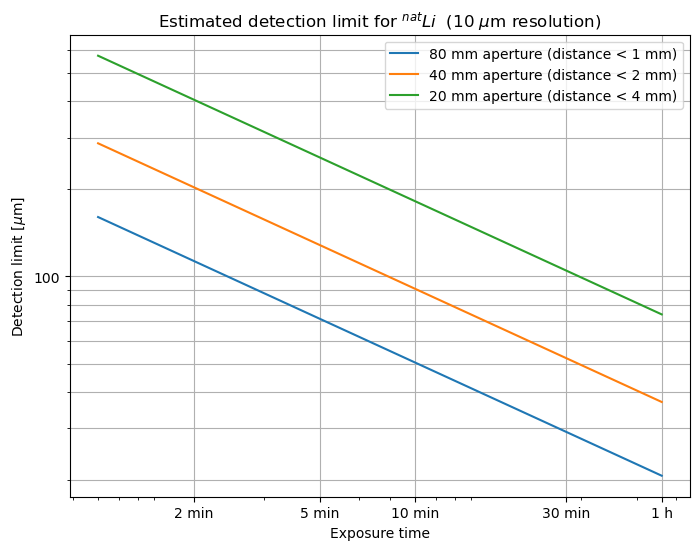

In [68]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_nat_n80)
plt.loglog(exp_time, dlim_thick_li_nat_n40)
plt.loglog(exp_time, dlim_thick_li_nat_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{nat}Li$  (10 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 1 mm)', '40 mm aperture (distance < 2 mm)', '20 mm aperture (distance < 4 mm)'])
plt.show()

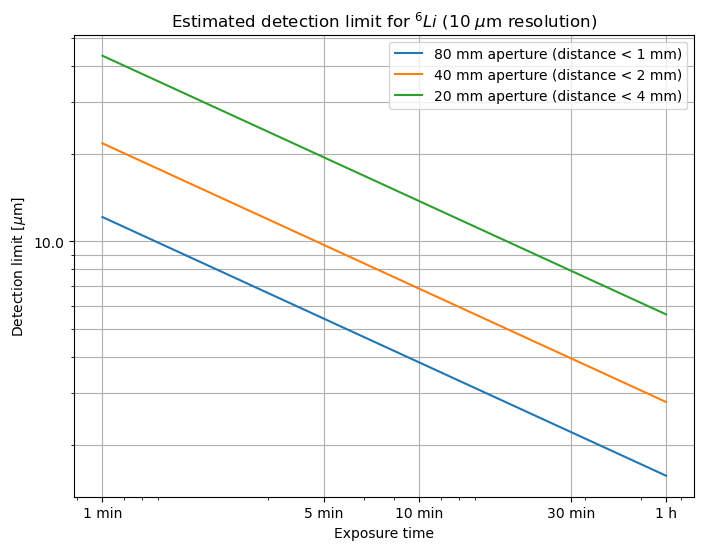

In [69]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_6_n80)
plt.loglog(exp_time, dlim_thick_li_6_n40)
plt.loglog(exp_time, dlim_thick_li_6_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([60, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['1 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{6}Li$ (10 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 1 mm)', '40 mm aperture (distance < 2 mm)', '20 mm aperture (distance < 4 mm)'])
plt.show()

In [77]:
# 650 pixles for the 13mm diameter Si SEI
# 11.344 from 1 degree alignment precision (13000um * sin(1 degree) / 20um)
pixel_size = 13.5
num_pixel = 200/pixel_size + 13000 * np.sin(np.pi/180) / pixel_size
print(num_pixel)
volume_limit_um = pixel_size**2 * np.sqrt(650 * 32) * 13 / 2.57
volume_limit_cm = volume_limit_um / 10**12
mass_limit_g = volume_limit_cm * 0.464
print(volume_limit_cm)
print(mass_limit_g)

31.62083582849523
1.3295645695553398e-07
6.169179602736778e-08


### Calculations for 20 $\mu$m resolution

In [37]:
resolution = 20 * 1e-4 # spatial resolution set to 10 um

In [38]:
dlim_thick_li_nat_n20, dlim_thick_li_6_n20 = calc_dlim(n_flux_n20, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n40, dlim_thick_li_6_n40 = calc_dlim(n_flux_n40, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n80, dlim_thick_li_6_n80 = calc_dlim(n_flux_n80, dqe, resolution, exp_time, prec_limit)

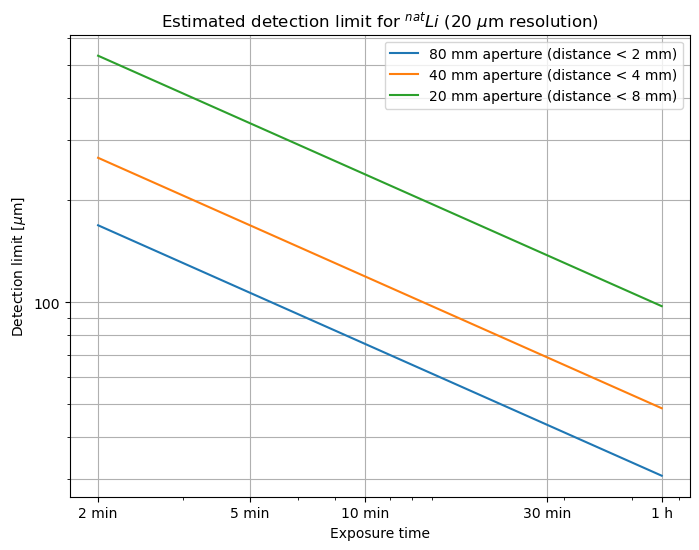

In [39]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_nat_n80)
plt.loglog(exp_time, dlim_thick_li_nat_n40)
plt.loglog(exp_time, dlim_thick_li_nat_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{nat}Li$ (20 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 2 mm)', '40 mm aperture (distance < 4 mm)', '20 mm aperture (distance < 8 mm)'])
plt.show()

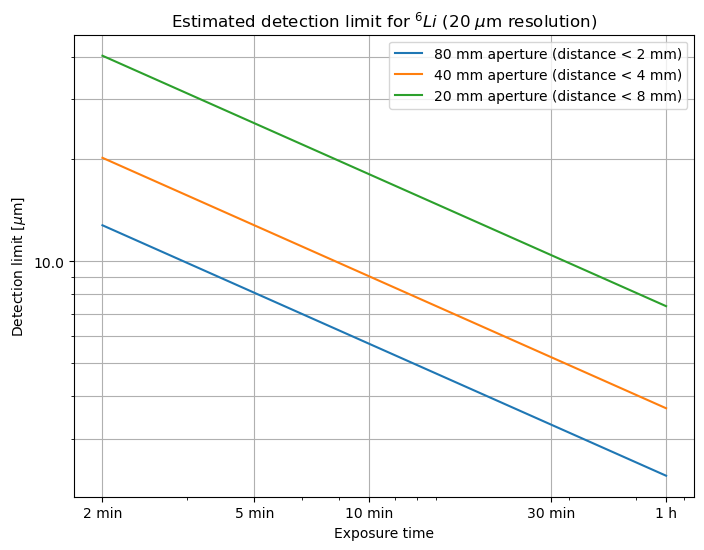

In [40]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_6_n80)
plt.loglog(exp_time, dlim_thick_li_6_n40)
plt.loglog(exp_time, dlim_thick_li_6_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{6}Li$ (20 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 2 mm)', '40 mm aperture (distance < 4 mm)', '20 mm aperture (distance < 8 mm)'])
plt.show()

### Calculations for 50 $\mu$m resolution

In [41]:
resolution = 50 * 1e-4 # spatial resolution set to 10 um

In [42]:
dlim_thick_li_nat_n20, dlim_thick_li_6_n20 = calc_dlim(n_flux_n20, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n40, dlim_thick_li_6_n40 = calc_dlim(n_flux_n40, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n80, dlim_thick_li_6_n80 = calc_dlim(n_flux_n80, dqe, resolution, exp_time, prec_limit)

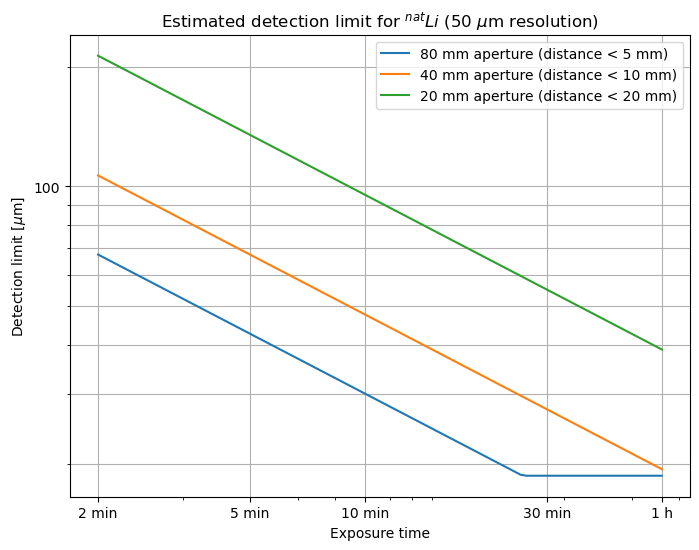

In [43]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_nat_n80)
plt.loglog(exp_time, dlim_thick_li_nat_n40)
plt.loglog(exp_time, dlim_thick_li_nat_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{nat}Li$ (50 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 5 mm)', '40 mm aperture (distance < 10 mm)', '20 mm aperture (distance < 20 mm)'])
plt.show()

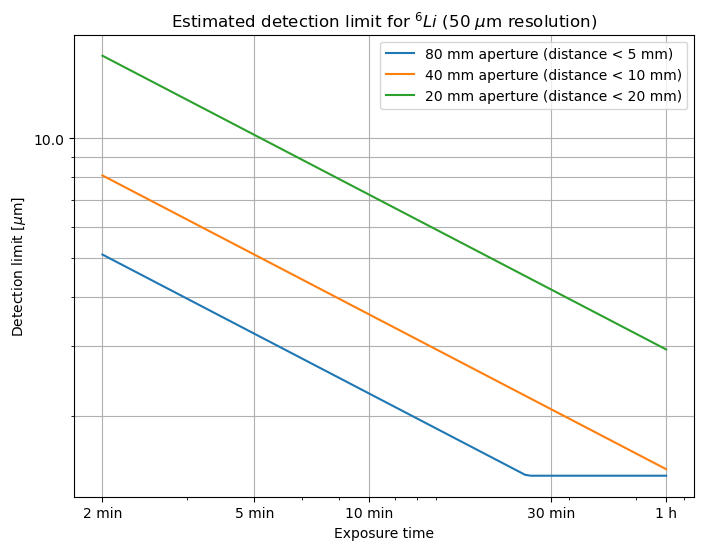

In [44]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_6_n80)
plt.loglog(exp_time, dlim_thick_li_6_n40)
plt.loglog(exp_time, dlim_thick_li_6_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{6}Li$ (50 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 5 mm)', '40 mm aperture (distance < 10 mm)', '20 mm aperture (distance < 20 mm)'])
plt.show()

### Calculations for 100 $\mu$m resolution

In [45]:
resolution = 100 * 1e-4 # spatial resolution set to 10 um

In [46]:
dlim_thick_li_nat_n20, dlim_thick_li_6_n20 = calc_dlim(n_flux_n20, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n40, dlim_thick_li_6_n40 = calc_dlim(n_flux_n40, dqe, resolution, exp_time, prec_limit)
dlim_thick_li_nat_n80, dlim_thick_li_6_n80 = calc_dlim(n_flux_n80, dqe, resolution, exp_time, prec_limit)

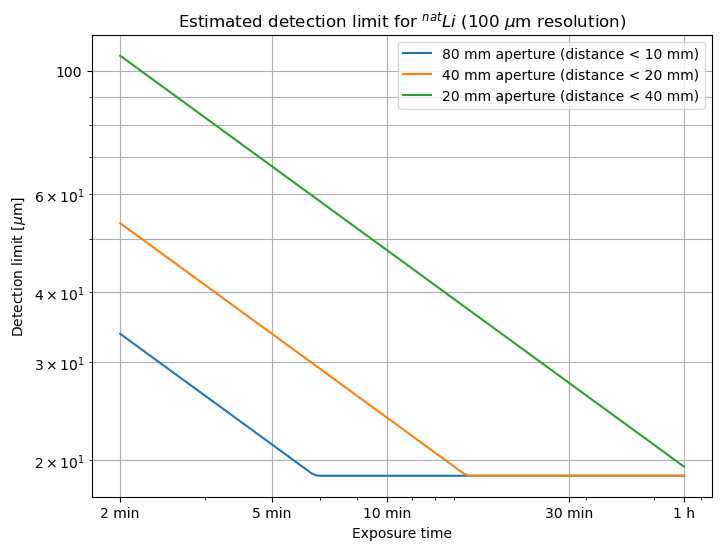

In [47]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_nat_n80)
plt.loglog(exp_time, dlim_thick_li_nat_n40)
plt.loglog(exp_time, dlim_thick_li_nat_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{nat}Li$ (100 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 10 mm)', '40 mm aperture (distance < 20 mm)', '20 mm aperture (distance < 40 mm)'])
plt.show()

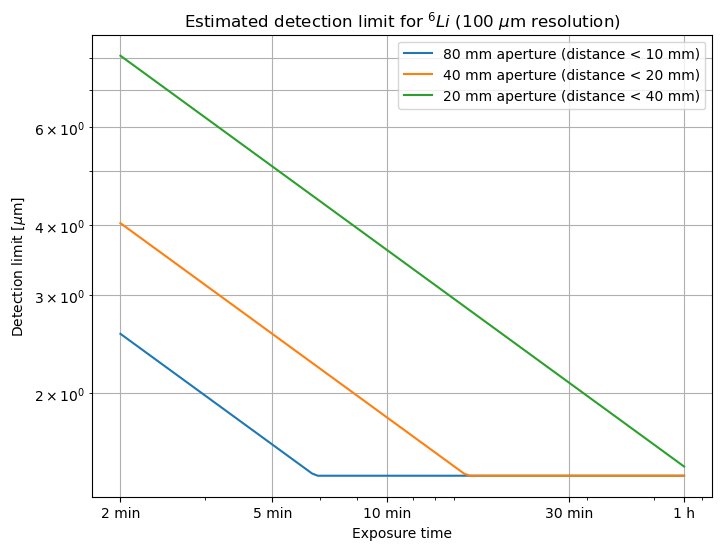

In [48]:
plt.figure(figsize=(8,6))
ax = plt.axes(xscale='log', yscale='log')
ax.grid(which='major', axis='x')
ax.grid(which='both', axis='y')
plt.loglog(exp_time, dlim_thick_li_6_n80)
plt.loglog(exp_time, dlim_thick_li_6_n40)
plt.loglog(exp_time, dlim_thick_li_6_n20)
ax.xaxis.set_major_locator(plt.FixedLocator([120, 300, 600, 1800, 3600]))
ax.xaxis.set_major_formatter(plt.FixedFormatter(['2 min', '5 min', '10 min', '30 min', '1 h']))
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
plt.xlabel('Exposure time')
plt.ylabel('Detection limit [$\mu$m]')
plt.title('Estimated detection limit for $^{6}Li$ (100 $\mu$m resolution)')
plt.legend(['80 mm aperture (distance < 10 mm)', '40 mm aperture (distance < 20 mm)', '20 mm aperture (distance < 40 mm)'])
plt.show()

### Mass Resolution

In [85]:
pixel_size = 5
thickness_limit = 10.8
pixel_std = pixel_size**2 * thickness_std/2.57
print(pixel_std)

40.87874154037155


In [107]:
pixel_number = 100 * 13000 / pixel_size**2
volume_std = pixel_std * pixel_number**0.5
mass_std = volume_std * 0.46e-12
print("number of pixels =",pixel_number)
print("total volume std =",volume_std,"um^3")
print("total mass std =",mass_std,"g")

number of pixels = 52000.0
total volume std = 9321.787302662184 um^3
total mass std = 4.288022159224604e-09 g


In [110]:
sei_volume = 13000**2 * np.pi * 0.05
percentage_error = volume_std / sei_volume
print("SEI volume =",sei_size,"um^3")
print("percentage volume error=",percentage_error)


SEI volume = 26546457.922833756 um^3
percentage volume error= 0.00035114994737750347
